# 04 — Lunar TCL−TCB against LTE440

**What this notebook does:** validates TEMPUS's lunar time scale TCL−TCB against LTE440
(Lu et al. 2025), the only independent lunar time ephemeris, and separates *implementation*
differences from *ephemeris* differences.

**Why the separation matters.** LTE440 is built on DE440 while Klioner's lunar series is built
on INPOP19a. Comparing across those two mixes a question about TEMPUS with a question about the
ephemerides. Section 1 holds the ephemeris fixed at DE440 and varies only the implementation —
that is the validation. Section 3 does the reverse and is *not* a validation of anything; it
measures how far apart INPOP19a and DE440 place the Moon, with Klioner as the control.

TEMPUS against Klioner on a common ephemeris is covered for all eleven bodies, the Moon
included, in **notebook 02**; it is not repeated here.

**Key results:** on DE440, agreement with LTE440 at ~10⁻¹⁷ s s⁻¹. Across ephemerides,
the INPOP19a-vs-DE440 lunar difference is ~10⁻¹⁹ s s⁻¹ with a sub-nanosecond peak — smaller than
the dynamical-model residual on DE440 itself — and Klioner, evaluated at the TCB epochs of the same
events, lands on the same value. Section 3 also shows what goes wrong when a TCB-argument series is
compared with a TDB-argument one at equal epoch *numbers*: a spurious drift of exactly L_C·L_B and
tens of ns of periodic error.

**Required data files**
- `../data/kernels/de440.bsp`, `gm_de440.tpc`, `sb441-n373s.bsp`, `header.440`, `header_kbo.440`
- `../data/LTE440-tcl_tdb/lte440.bsp`, `lte440.tpc` — LTE440 is not fetched by the download scripts; get both files from <https://github.com/xlucn/LTE440/releases>
- `../data/ephem/inpop19a_TDB_m100_p100_tt.dat` (the **TDB** flavour, so the run sits on the
  same TDB grid as the DE440 runs) and
  `../data/time_ephem/tcx19a_TCL_m100_p100_asc_pos_TCB.asc` (Section 3 only)

## 0 · The dynamical models behind each product

The comparisons below are only interpretable if one knows what each ephemeris actually
integrates and accounts for. This is the lunar counterpart of the missing bodies discussion in notebook 03.

### DE440 (Park et al. 2021, AJ 161, 105)

DE440 integrates **the same body set as DE430** — the Sun, the eight planetary barycentres, the
Moon, the Pluto barycentre and **343 asteroids** — and adds a Kuiper-belt model that DE430 did
not have:

| component | DE430 | DE440 |
|---|---|---|
| planets, Moon, Pluto | yes | yes |
| main-belt asteroids | 343 | 343 (same set, re-fitted masses) |
| individual KBOs | none | **30** |
| KBO ring | none | **36 equal-mass points at 44 AU** |
| lunar core/mantle damping | yes | yes (DE441 omits it) |

Two consequences matter here:

1. **TEMPUS can supply the 343 asteroids and the 30 individual KBOs** — they are real bodies in
   `sb441-n373s.bsp` (n373 = 343 + 30) with GMs in `header.440` / `header_kbo.440`. It **cannot**
   supply the 36-point KBO ring.
2. **DE441 is the same fit without lunar core damping**, which is what lets it integrate far
   backwards without divergence. DE440 is the right choice for a 200 yr window centred on J2000;
   DE441 would be needed for millennia.

### DE430 (Folkner et al. 2014, IPN PR 42-196) — side note

DE430 carries the same 343 asteroids but no KBO population at all, individual or ring. Its lunar
model includes a fluid core and tidal dissipation, and its **Principal Axis (PA) frame is the
reference realisation used for lunar body-fixed work**.

For **ILuRF / ILuRS 2026 TEMPUS was used with DE430** as the better ephemeris for Moon
applications. That choice concerns the *frame* realisation, not the
Kuiper-belt model, so it does not conflict with using DE440 here: this notebook validates a time
transformation, it does not realise a body-fixed frame.

### A practical difference between SPK and INPOP files

INPOP `.dat` files carry their own time-ephemeris series (CALCEPH targets 16/17), so TEMPUS can
convert TT↔TDB↔TCB self-consistently from the file. An SPK such as `de440.bsp` does not, so for
DE440 the integration span is given directly in the file's own scale. This is harmless for the
comparison, because TEMPUS and LTE440 are evaluated on the *same* split-JD grid — only the
shared epochs matter, not their label in TT.

What is **not** harmless is mixing argument time scales. `de440.bsp` and `lte440.bsp` are
functions of TDB; Klioner's `.asc` and a TEMPUS run on the TCB flavour of INPOP19a are functions
of TCB. The two epoch numbers for one event differ by L_B·(t − 1977) ≈ 47 s at ±100 yr, so
evaluating a TDB product at TCB epoch numbers samples a *different event*: TCL−TCB shifts by its
rate × 47 s (a drift of exactly L_C·L_B = 2.30×10⁻¹⁶) and its periodic terms by tens of ns. Section
3 therefore runs INPOP19a in its **TDB** flavour on the DE440 grid and converts that grid to TCB
before evaluating Klioner.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

from calcephpy import CalcephBin, Constants

from tempus import TimeScalar
from tempus.model import TimeGrid, jd_tdb_to_tcb
from tempus.chebycode import ChebySeries
from tempus.output import read_csv
from nb_utils import DAY_S, plot_compare_2timescales, run_tempus_integration

# --- inputs -----------------------------------------------------------------
KDIR        = Path("../data/kernels").resolve()
eph_de440   = [KDIR / "de440.bsp", KDIR / "gm_de440.tpc"]
ast_file    = KDIR / "sb441-n373s.bsp"          # 343 MBAs + 30 KBOs
gm_mba      = KDIR / "header.440"
gm_kbo      = KDIR / "header_kbo.440"

eph_19a_tdb = Path("../data/ephem/inpop19a_TDB_m100_p100_tt.dat").resolve()  # TDB flavour
gm_19a      = Path("../data/ephem/header_mba.19a").resolve()   # as in notebook 03
klioner_tcl = Path("../data/time_ephem/tcx19a_TCL_m100_p100_asc_pos_TCB.asc").resolve()
lte440      = [Path("../data/LTE440-tcl_tdb/lte440.bsp").resolve(),
               Path("../data/LTE440-tcl_tdb/lte440.tpc").resolve()]

# --- outputs: named once, so the run cells and the load cells never disagree --
OUT = Path("../output").resolve()
CSV = {
    "de440_base": OUT / "nb04_moon_200yr_DE440_base.csv",   # planets only
    "de440_mba":  OUT / "nb04_moon_200yr_DE440_mba.csv",    # + 343 MBAs
    "de440_all":  OUT / "nb04_moon_200yr_DE440_all.csv",    # + 343 MBAs + 30 KBOs
    "inpop19a":     OUT / "nb04_moon_200yr_INPOP19aTDB.csv",      # planets only, DE440 grid
    "inpop19a_ast": OUT / "nb04_moon_200yr_INPOP19aTDB_ast.csv",  # + small bodies, DE440 grid
}

J2000_TT = 2451545.0
NS_CY    = 3.168808781e-19          # 1 ns/cy expressed in s/s
results  = {}


def residual(y1, y2, et, label, unit="ns"):
    """Drift [s/s] and residual's peak of y1 - y2 to results dict, and print it."""
    d = np.asarray(y1) - np.asarray(y2)
    slope, icpt, *_ = stats.linregress(et, d)
    peak = np.max(np.abs(d - (slope * et + icpt)))
    results[label] = (slope, peak, unit)
    scale = 1e12 if unit == "ps" else 1e9
    print(f"{label:46s} {slope:+.3e} s/s ({slope / NS_CY:+9.3f} ns/cy)  peak {peak * scale:9.3f} {unit}")
    return slope, peak


def load_tcl(key):
    """Read a TEMPUS run and return split JD, et, and TCL-TCB (sign flipped from TCB-TCX)."""
    c = read_csv(CSV[key])[0]
    return (np.asarray(c["JD_int"], np.int64), np.asarray(c["JD_frac"], float),
            np.asarray(c["SecondsPastJ2000"], float),
            -np.asarray(c["TCB_minus_TCX"], float))

In [2]:
# --- LTE440 reader (follows the authors' own reference implementation) --------
# LTE440 stores TCL-TDB; these constants convert it to TCL-TCB.
L_B    = 1.550519768e-8
TDB0   = -65.5e-6
T0_JD1 = 2443144.5
T0_JD2 = 0.0003725 + TDB0 / 86400


def lte440_tcl_tcb(eph, jd1, jd2=0.0) -> float:
    """TCL-TCB from the LTE440 kernel at split JD (jd1, jd2)."""
    target   = eph.getidbyname("TIME_TCLMTDB", Constants.USE_NAIFID)
    unit     = Constants.UNIT_SEC | Constants.UNIT_KM | Constants.USE_NAIFID
    periodic = eph.compute_unit(jd1, jd2, target, 1000000000, unit)[0]
    drift    = eph.getconstant(f"BODY{target}_RATE")
    dTDB     = ((jd1 - T0_JD1) + (jd2 - T0_JD2)) * 86400
    tcl_tdb  = periodic + drift * dTDB
    return tcl_tdb + TDB0 - L_B / (1 - L_B) * dTDB


def lte440_on_grid(jdi, jdf):
    """Evaluate LTE440 TCL-TCB on a split-JD grid."""
    eph = CalcephBin.open([str(p) for p in lte440])
    try:
        return np.array([lte440_tcl_tcb(eph, int(a), float(b)) for a, b in zip(jdi, jdf)])
    finally:
        eph.close()

## 1 · TCL−TCB on DE440: TEMPUS vs LTE440

The ephemeris is fixed at DE440 and only the implementation varies, so this is the validation.
Three runs are made so the small-body contribution can be attributed rather than assumed:

| run | perturbers |
|---|---|
| `base` | Sun, planets, Pluto only |
| `mba`  | + 343 main-belt asteroids |
| `all`  | + 343 MBAs **and** the 30 individual KBOs |

`all` is the closest TEMPUS can get to DE440's own model — everything except the 36-point ring.

**The next cell is the expensive one** (three 200 yr integrations, the asteroid runs dominating).
It writes CSVs and is skipped when they exist; every later cell reads those files, so a repeat
session can run straight past it.

In [3]:
# ---- COSTLY: three 200 yr DE440 integrations. Skipped when the CSVs exist. ----
# An SPK carries no time-ephemeris series, so the span is given in the file's own scale.
start440 = TimeScalar(int(J2000_TT) - 36525, np.float64(0.0))
end440   = TimeScalar(int(J2000_TT) + 36525, np.float64(0.0))

de440_runs = {
    "de440_base": {},
    "de440_mba":  dict(asteroid_file=ast_file, asteroid_gm_header=gm_mba),
    "de440_all":  dict(asteroid_file=ast_file, asteroid_gm_header=[gm_mba, gm_kbo]),
}

for key, extra in de440_runs.items():
    if CSV[key].is_file():
        print(f"  have {CSV[key].name}")
        continue
    run_tempus_integration(
        eph_de440, start440, end440, jd_step=0.75, out=CSV[key], zero=True,
        target="MOON", center="SSB", ext="auto", integrator="am12", **extra,
    )

CALCEPH timescale: 1 (TDB)
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003724992418982 (TDB) (shift -36.024823013013318 s)
Approx. mean drift (TCB-TCX): 1.280912 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb04_moon_200yr_DE440_base.csv
CALCEPH timescale: 1 (TDB)
Loaded GM header 'header.440': 409 new (header values take priority).
Skipped 30 asteroids without GM constants.
Using 343 auto-discovered asteroids (positions + GM available).
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003724992418982 (TDB) (shift -36.024823024447286 s)
Approx. mean drift (TCB-TCX): 1.280912 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb04_moon_200yr_DE440_mba.csv
CALCEPH timescale: 1 (TDB)
Loaded GM header 'header.440': 409 new (header values take priority).
Loaded GM header 'header_kbo.440': 30 new (header values take priority).
Using 373 auto-discovered asteroids (positions + GM available).
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003724992418982 (TDB) (

In [4]:
# Reads the CSVs written above; independent of that cell's runtime state.
jdi, jdf, et440, _ = load_tcl("de440_all")
lte = lte440_on_grid(jdi, jdf)

for key, label in [("de440_base", "TEMPUS(DE440, planets) - LTE440"),
                   ("de440_mba",  "TEMPUS(DE440, +343 MBA) - LTE440"),
                   ("de440_all",  "TEMPUS(DE440, +343 MBA +30 KBO) - LTE440")]:
    *_, y = load_tcl(key)
    residual(lte, y, et440, label)

TEMPUS(DE440, planets) - LTE440                -2.376e-17 s/s (  -74.978 ns/cy)  peak     0.194 ns
TEMPUS(DE440, +343 MBA) - LTE440               -1.905e-17 s/s (  -60.113 ns/cy)  peak     0.192 ns
TEMPUS(DE440, +343 MBA +30 KBO) - LTE440       -1.640e-17 s/s (  -51.766 ns/cy)  peak     0.043 ns


LTE440 linear drift: -1.4825359793517396e-08 s/s, -1.2809110861599031 ms/day
TEMPUS (DE440) linear drift: -1.4825359777113591e-08 s/s, -1.2809110847426142 ms/day
Detrended TEMPUS (DE440) min/max: -1.807e-03, 1.824e-03 s


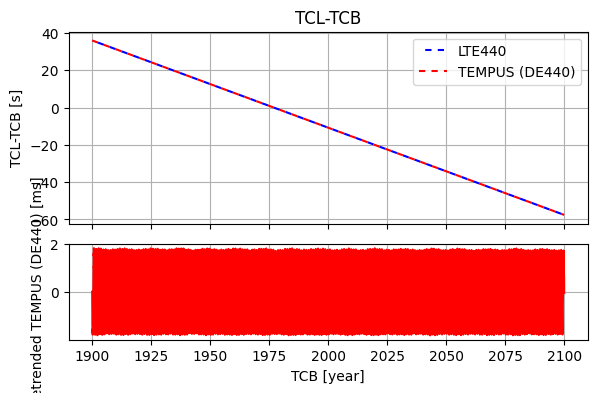

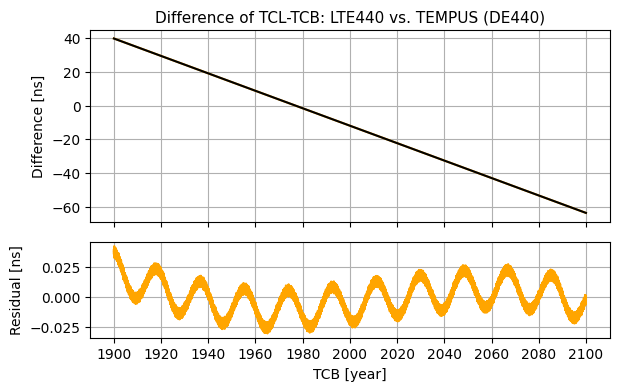

Drift slope (s/s): -1.6403793436764905e-17
Average drift per day (ps/day): -1.4172877529364878
Average drift per century (ns/cy): -51.76643517600521
Min and Max of detrended TCL-TCB (ns): -0.0306, 0.0427


In [5]:
*_, y = load_tcl("de440_all")
plot_compare_2timescales(et440, lte, "LTE440", y, "TEMPUS (DE440)",
                         label="TCL-TCB", x_tick=20, overview=True, paper_mode=True)

## 2 · What the 36-point KBO ring is worth

DE440 represents the Kuiper belt beyond its 30 named objects as a ring of 36 equal-mass points
at 44 AU. TEMPUS cannot include it, so if the ring enters DE440's own lunar solution it should
leave an irreducible residual once the 30 KBOs have been supplied.

A ring seen from well inside it is a nearly constant potential, so a missing ring mass $M$ at
radius $r$ appears as a **constant rate offset** $U/c^2 = GM/(rc^2)$ — a linear drift in
TCL−TCB, not a periodic term. The cell below inverts the measured drift into the mass it would
imply, which can then be checked against the ring mass published for DE440.

Notebook 03 found the analogous INPOP19a rings to be *invisible* to the distributed TCG−TCB
series, so a null result here is a meaningful outcome rather than a failed test.

In [6]:
G, ME, AU, C = 6.674e-11, 5.9722e24, 1.495978707e11, 299792458.0
r_ring = 44.0 * AU

print("Drift after each stage of the perturber set:")
for label in ("TEMPUS(DE440, planets) - LTE440",
              "TEMPUS(DE440, +343 MBA) - LTE440",
              "TEMPUS(DE440, +343 MBA +30 KBO) - LTE440"):
    print(f"  {label:46s} {results[label][0]:+.3e} s/s")

drift_all = results["TEMPUS(DE440, +343 MBA +30 KBO) - LTE440"][0]
implied_M = abs(drift_all) * C**2 * r_ring / G
print()
print(f"residual drift with every available small body : {drift_all:+.3e} s/s")
print(f"mass at 44 AU that would explain it            : {implied_M / ME:.4f} M_earth")
print()
print("Check `implied_M` against the DE440 KBO ring mass in Park et al. (2021).")
print("A value far below it means the ring does not propagate into LTE440 -- the")
print("DE440 analogue of the INPOP19a result in notebook 03.")

Drift after each stage of the perturber set:
  TEMPUS(DE440, planets) - LTE440                -2.376e-17 s/s
  TEMPUS(DE440, +343 MBA) - LTE440               -1.905e-17 s/s
  TEMPUS(DE440, +343 MBA +30 KBO) - LTE440       -1.640e-17 s/s

residual drift with every available small body : -1.640e-17 s/s
mass at 44 AU that would explain it            : 0.0243 M_earth

Check `implied_M` against the DE440 KBO ring mass in Park et al. (2021).
A value far below it means the ring does not propagate into LTE440 -- the
DE440 analogue of the INPOP19a result in notebook 03.


## 3 · Crossing ephemerides: what an INPOP19a-vs-DE440 row really measures

Running TEMPUS on INPOP19a and comparing against LTE440 mixes the transformation with the
difference between two lunar dynamical models. Klioner is the control: an independent
implementation *on the same INPOP19a*. If he departs from LTE440 by the same amount, the
residual belongs to the ephemerides and no implementation on INPOP19a could avoid it.

**Everything in this section is on the DE440 grid of Section 1**, which is a TDB grid. The
INPOP19a runs therefore use the TDB flavour of the file with the DE440 span, so `lte` from
Section 1 is already the right reference; Klioner's series is a function of TCB and is evaluated
at the TCB epochs of the same events (`jd_tdb_to_tcb`). Section 3.1 shows what the comparison
gives when this is *not* done.

Two INPOP19a runs are made. The planets-only one isolates the ephemeris difference most
starkly; the second adds INPOP19a's own small-body set so the row can be read against the
fully-populated DE440 run of Section 1 rather than against a deliberately sparser model.

The next cell is again the costly one and is skipped when its CSVs exist.


In [7]:
# ---- COSTLY: two 200 yr INPOP19a integrations. Skipped when the CSVs exist. ----
# TDB flavour of INPOP19a on the DE440 span, so the grid epochs coincide with Section 1.
inpop_runs = {
    "inpop19a":     {},
    "inpop19a_ast": dict(asteroid_file=ast_file, asteroid_gm_header=gm_19a),
}

for key, extra in inpop_runs.items():
    if CSV[key].is_file():
        print(f"  have {CSV[key].name}")
        continue
    # TEMPUS prints how many small bodies it actually resolved a GM for.
    run_tempus_integration(
        eph_19a_tdb, start440, end440, jd_step=0.75, out=CSV[key], zero=True,
        target="MOON", center="SSB", ext="auto", integrator="am12", **extra,
    )


Ephemeris version: INPOP19A
CALCEPH timescale: 1 (TDB)
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003724992418982 (TDB) (shift -36.024823012350517 s)
Approx. mean drift (TCB-TCX): 1.280912 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb04_moon_200yr_INPOP19aTDB.csv
Ephemeris version: INPOP19A
CALCEPH timescale: 1 (TDB)
Loaded GM header 'header_mba.19a': 350 new (header values take priority).
Skipped 20 asteroids without GM constants.
Using 353 auto-discovered asteroids (positions + GM available).
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003724992418982 (TDB) (shift -36.024823027536129 s)
Approx. mean drift (TCB-TCX): 1.280912 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb04_moon_200yr_INPOP19aTDB_ast.csv


In [ ]:
jdi19, jdf19, et19, tcl19 = load_tcl("inpop19a")
assert np.array_equal(jdi19, jdi) and np.allclose(jdf19, jdf), "INPOP19a run is not on the DE440 grid"

# Klioner's TCL is a function of TCB: evaluate it at the TCB epochs of the same events.
grid_tcb = jd_tdb_to_tcb(TimeGrid(jd_int=jdi19, jd_frac=jdf19))
kl = ChebySeries.from_asc(str(klioner_tcl)).evaluate(grid_tcb.jd_int, grid_tcb.jd_frac)

residual(lte, tcl19, et19, "TEMPUS(19a, planets) - LTE440(DE440)")

# Same run with INPOP19a's own small-body set, so the cross-ephemeris row is
# compared like-for-like with the fully-populated DE440 run of Section 1.
*_, tcl19a = load_tcl("inpop19a_ast")
residual(lte, tcl19a, et19, "TEMPUS(19a, +small bodies) - LTE440(DE440)")

residual(lte, kl, et19, "Klioner(19a) - LTE440(DE440)") 

# The ephemeris difference on its own, with no third product in the loop.
*_, y440 = load_tcl("de440_base")
residual(y440, tcl19, et19, "TEMPUS(19a, planets) - TEMPUS(DE440, planets)") 

a = results["TEMPUS(19a, planets) - LTE440(DE440)"][0]
b = results["Klioner(19a) - LTE440(DE440)"][0]
print()
print(f"ratio of the two cross-ephemeris drifts: {a / b:.4f}")
print("Near 1 means TEMPUS and Klioner, both on INPOP19a, sit at the same distance from LTE440.")


TEMPUS(19a, planets) - LTE440(DE440)           -2.390e-17 s/s (  -75.435 ns/cy)  peak     0.366 ns
TEMPUS(19a, +small bodies) - LTE440(DE440)     -1.771e-17 s/s (  -55.890 ns/cy)  peak     0.257 ns
Klioner(19a) - LTE440(DE440)                   -2.391e-17 s/s (  -75.453 ns/cy)  peak     0.365 ns
TEMPUS(19a, planets) - TEMPUS(DE440, planets)  -1.448e-19 s/s (   -0.457 ns/cy)  peak     0.234 ns

ratio of the two cross-ephemeris drifts: 0.9998
Near 1 means TEMPUS and Klioner, both on INPOP19a, sit at the same distance from LTE440.


### 3.1 · The equal-epoch-number trap

The check below evaluates LTE440 at the **TCB** epoch numbers of the grid, as if they were TDB —
which is what one gets by comparing a TCB-argument product with a TDB-argument one without
converting. The residual against the same TEMPUS run then acquires a drift of exactly
L_C·L_B and a periodic error of tens of ns, neither of which has anything to do with the
ephemerides. An earlier version of this notebook (and of the paper's Table 2) reported that
artefact as the INPOP19a-vs-DE440 difference.


In [9]:
L_C = 1.48082686741e-8
lte_at_tcb_numbers = lte440_on_grid(grid_tcb.jd_int, grid_tcb.jd_frac)
d = np.asarray(lte_at_tcb_numbers) - (tcl19)
slope, icpt, *_ = stats.linregress(et19, d)
peak = np.max(np.abs(d - (slope * et19 + icpt)))
print(f"LTE440 at TCB epoch numbers - TEMPUS(19a): drift {slope:+.3e} s/s, peak {peak * 1e9:.1f} ns")
print(f"L_C * L_B                                : {L_C * L_B:+.3e} s/s")
print(f"true INPOP19a-vs-DE440 difference (above) : "
      f"{results['TEMPUS(19a, planets) - TEMPUS(DE440, planets)'][0]:+.3e} s/s")


LTE440 at TCB epoch numbers - TEMPUS(19a): drift -2.538e-16 s/s, peak 40.0 ns
L_C * L_B                                : +2.296e-16 s/s
true INPOP19a-vs-DE440 difference (above) : -1.448e-19 s/s


## 4 · Summary — numbers used in the paper

The DE440 rows are validations: one ephemeris, two implementations. The cross-ephemeris rows
are not a validation of anything — they measure how far apart INPOP19a and DE440 place the
Moon. On one TDB grid that difference is at the 10⁻¹⁹ s s⁻¹ level with a sub-nanosecond peak,
i.e. the choice between the two ephemerides moves TCL−TCB by less than the small-body model
does (notebook 05, block b).


In [10]:
print(f"{'comparison':46s} {'drift [s/s]':>13s} {'ns/cy':>11s} {'peak':>14s}")
print("-" * 90)
for label, (drift, peak, unit) in results.items():
    print(f"{label:46s} {drift:13.5e} {drift / NS_CY:11.3f} "
          f"{peak * (1e12 if unit == 'ps' else 1e9):11.4f} {unit}")

comparison                                       drift [s/s]       ns/cy           peak
------------------------------------------------------------------------------------------
TEMPUS(DE440, planets) - LTE440                 -2.37590e-17     -74.978      0.1941 ns
TEMPUS(DE440, +343 MBA) - LTE440                -1.90485e-17     -60.113      0.1920 ns
TEMPUS(DE440, +343 MBA +30 KBO) - LTE440        -1.64038e-17     -51.766      0.0427 ns
TEMPUS(19a, planets) - LTE440(DE440)            -2.39038e-17     -75.435      0.3664 ns
TEMPUS(19a, +small bodies) - LTE440(DE440)      -1.77104e-17     -55.890      0.2571 ns
Klioner(19a) - LTE440(DE440)                    -2.39095e-17     -75.453      0.3651 ns
TEMPUS(19a, planets) - TEMPUS(DE440, planets)   -1.44753e-19      -0.457      0.2343 ns
